<a href="https://colab.research.google.com/github/Yunuenn/EstadisticaInferencial2026A/blob/main/ProblemarioU4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Ejercicio 1**

1. **Comparación de cuatro métodos de ensamble:** Un equipo de mejora investiga el efecto de cuatro métodos de ensamble A, B, C y D, sobre el tiempo de ensamble en minutos. En primera instancia, la estrategia experimental es aplicar cuatro veces los cuatro métodos de ensamble en orden completamente aleatorio (las 16 pruebas en orden aleatorio). Los tiempos de ensamble obtenidos se muestran en la tabla 3.1. Si se usa el diseño completamente al azar (DCA), se supone que, además del método de ensamble, no existe ningún otro factor que influya de manera significativa sobre la variable de respuesta (tiempo de ensamble).

| Método de ensamble | A  | B  | C  | D  |
|--------------------|----|----|----|----|
|                    | 6  | 7  | 11 | 10 |
|                    | 8  | 9  | 16 | 12 |
|                    | 7  | 10 | 11 | 11 |
|                    | 8  | 8  | 13 | 9  |


- Factor: Método
- Niveles de medición: A, B, C, D
- Variable de respuesta: Tiempo de ensamble (en minutos)
- Objetivo: Minimizar

In [766]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problemario_01.csv"
df = pd.read_csv(link_csv)
df
# Aranza Yunuen Pérez Sánchez

,metodo,tiempo
0,A,6
1,B,7
2,C,11
3,D,10
4,A,8
5,B,9
6,C,16
7,D,12
8,A,7
9,B,10


## **ANOVA (diferencia entre las medias)**

In [767]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("tiempo ~ C(metodo)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(metodo),69.5,3.0,9.4237,0.0018
Residual,29.5,12.0,NaN,NaN


### **Interpretación:** Según ANOVA, existe evidencia para decir que al menos uno de los métodos de ensamble tiene un tiempo promedio distinto a los demás, por lo que se rechaza HO con un valor-p = 0.0018

## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.2808008139238355


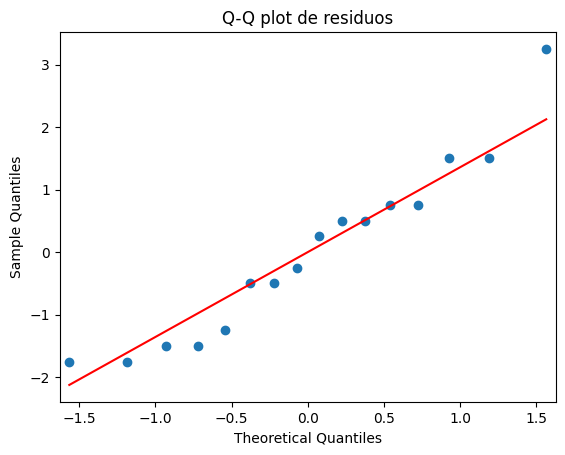

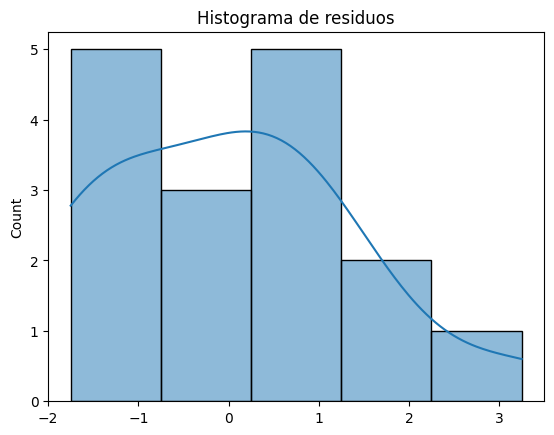

In [768]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Los resultados muestran que siendo el valor-p = 0.2808 no se rechaza la hipótesis nula de normalidad, por lo que los residuos de ANOVA siguen una distrbución normal y al menos un método de ensamble es confiable.

## **Levene (Homocedasticidad)**

In [769]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
grupo_M1 = df[df['metodo'] == 'A']['tiempo']
grupo_M2 = df[df['metodo'] == 'B']['tiempo']
grupo_M3 = df[df['metodo'] == 'C']['tiempo']
grupo_M4 = df[df['metodo'] == 'D']['tiempo']

stat, p = levene(grupo_M1, grupo_M2, grupo_M3, grupo_M4)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

# Aranza Yunuen Pérez Sánchez

Estadístico de Levene: 0.9474
p-valor: 0.4485


### **Interpretación:** El valor-p resultando en 0.4485, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas del tiempo de ensamble son similares entre los doferentes métodos.

## **Tukey**

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B     1.25 0.6805 -2.0416 4.5416  False
     A      C      5.5 0.0016  2.2084 8.7916   True
     A      D     3.25 0.0533 -0.0416 6.5416  False
     B      C     4.25  0.011  0.9584 7.5416   True
     B      D      2.0 0.3181 -1.2916 5.2916  False
     C      D    -2.25 0.2309 -5.5416 1.0416  False
---------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

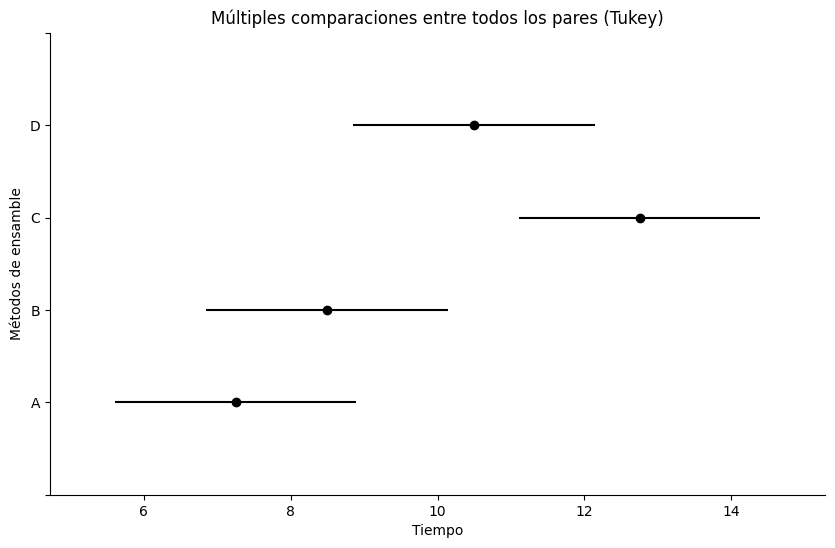

In [770]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['tiempo'], # Variable de respuesta
    groups=df['metodo'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Métodos de ensamble", xlabel="Tiempo")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Debido a que el supuesto ANOVA no aceptó la hipótesis nula, se realizó la prueba Tukey para revisar las medias. Tukey expone que solo existen diferencias significativas entre A y C y entre B y C.

## **Eta Cuadrado**

In [771]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(metodo)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.702


### **Interpretación:** Expone que el 70.2% de los cambios en los tiempos de ensamble se deben al método.

## **Potencia de la prueba**

In [772]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["metodo"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.7020
f de Cohen = 1.5349
Potencia de la prueba = 0.9956


### **Interpretación:** La potencia de la prueba indica la probabilidad de detectar una diferencia entre los métodos cuando existe, lo que resulta en 99.56% lo que indica que tiene una alta capacidad de detectar el efecto.

In [773]:
n_necesario = analisis_potencia.solve_power(
 effect_size=f_cohen,
 alpha=0.05,
 power=0.80, # Potencia de la prueba
 k_groups=k_grupos
)
print(f"Observaciones totales necesarias: {n_necesario:.2f}")
print(f"Observaciones por grupo: {np.ceil(n_necesario / k_grupos):.0f}")

# Aranza Yunuen Pérez Sánchez

Observaciones totales necesarias: 9.56
Observaciones por grupo: 3


## **CONCLUSIÓN:** Se puede decir gracias a la estadística que se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, el étodo de ensamble tiene un peso significativo en el tiempo. Conviene evitar el método C y utilizar el método A o B.

# **Ejercicio 2**

2. **Comparación de cuatro tipos de cuero:** Un fabricante de calzado desea mejorar la calidad de las suelas, las cuales se pueden hacer con uno de los cuatro tipos de cuero A, B, C y D disponibles en el mercado. Para ello, prueba los cueros con una máquina que hace pasar los zapatos por una superficie abrasiva; la suela de éstos se desgasta al pasarla por dicha superficie. Como criterio de desgaste se usa la pérdida de peso después de un número fijo de ciclos. Se prueban en orden aleatorio 24 zapatos, seis de cada tipo de cuero. Al hacer las pruebas en orden completamente al azar se evitan sesgos y las mediciones en un tipo de cuero resultan independientes de las demás. Los datos (en miligramos) sobre el desgaste de cada tipo de cuero se muestran en la tabla.

| Tipo de cuero | Observaciones                  | Promedio |
|---------------|--------------------------------|----------|
| A             | 264, 260, 258, 241, 262, 255 | 256.7    |
| B             | 208, 220, 216, 200, 213, 206 | 209.8    |
| C             | 220, 263, 219, 225, 230, 228 | 230.8    |
| D             | 217, 226, 215, 227, 220, 222 | 220.7    |

- Factor: Tipo de cuero
- Niveles de medición: A, B, C, D
- Variable de respuesta: Desgaste
- Objetivo: minimizar

In [774]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_02.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,Tipo,Desgaste
0,A,264
1,B,208
2,C,220
3,D,217
4,A,260
5,B,220
6,C,263
7,D,226
8,A,258
9,B,216


## **ANOVA (diferencia entre las medias)**

In [775]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("Desgaste ~ C(Tipo)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(Tipo),7019.4583,3.0,22.7554,0.0
Residual,2056.5000,20.0,NaN,NaN


### **Interpretación:** Según ANOVA, existe evidencia para decir que al menos uno de los tipos de cuero tiene un desgaste promedio distinto a los demás, por lo que se rechaza hipótesis nula con un valor-p = 0.0  y un estadístico = 22.7554

## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.009670145138301391


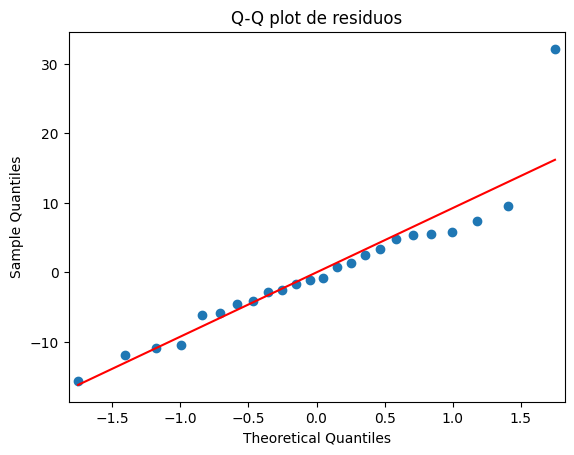

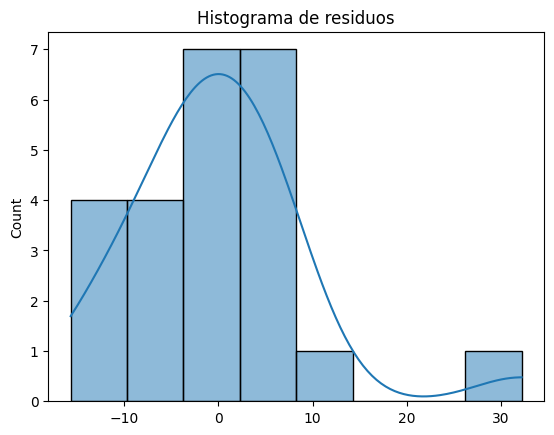

In [776]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Los resultados muestran que siendo el valor-p = 0.0097 sí se rechaza la hipótesis nula de normalidad, por lo que los residuos del ANOVA no siguen una distribución normal (como también se observa en la gráfica Q-Q plot) y debe tenerse en cuenta para emplear el box-cox para el desgaste entre tipos de cuero.

## **Levene (Homocedasticidad)**

In [777]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tipo_1 = df[df['Tipo'] == "A"]["Desgaste"]
tipo_2 = df[df['Tipo'] == "B"]["Desgaste"]
tipo_3 = df[df['Tipo'] == "C"]["Desgaste"]
tipo_4 = df[df['Tipo'] == "D"]["Desgaste"]

estadistico, valor_p_levene = levene(
    tipo_1,
    tipo_2,
    tipo_3,
    tipo_4,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.5797
Valor-p = 0.6351


### **Interpretación:** El valor-p resuñltando en 0.6351, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas del desgaste son similares entre los diferentes tipos de cuero.

## **Box-Cox**

Lambda óptimo: -3.7078


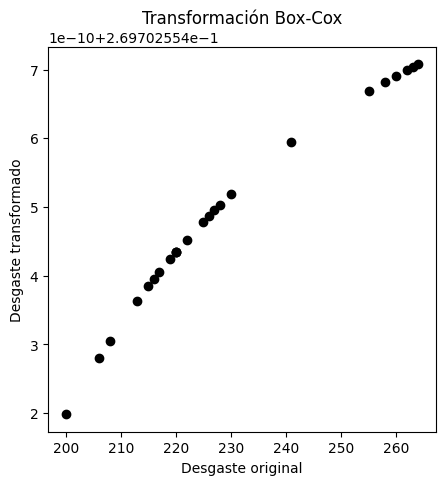

In [778]:

from scipy.stats import boxcox
import matplotlib.pyplot as plt

# Transformación Box-Cox
# Requiere que todos los valores sean mayores que cero

df["Desgaste_boxcox"], lambda_opt = boxcox(df["Desgaste"])

print(f"Lambda óptimo: {lambda_opt:.4f}")

# Visualización de la transformación
plt.figure(figsize=(5, 5), dpi=100)

plt.scatter(df["Desgaste"], df["Desgaste_boxcox"],
            color="black")

plt.title("Transformación Box-Cox")
plt.xlabel("Desgaste original")
plt.ylabel("Desgaste transformado")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Se utiliza Box-cox ya que en la prueba de Shapiro se rechaza la normalidad, lo que nos sirve para corregir el sesgo y acercar los datos a una distribución normal para el modelo. Lambda es significativamente alto en negativo, lo que ocasiona que la curva se doble hacia abajo.

## **ANOVA** (con variable transformada)

In [779]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('Desgaste_boxcox ~ C(Tipo)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(Tipo),0.0,3.0,23.3682,0.0
Residual,0.0,20.0,NaN,NaN


### **Interpretación:** Con la variable transformada el ANOVA sigue mostrando gran efecto del tipo de cuero, por lo que hay al menos un tipo de desgaste de cuerpo promedio diferente.

## **Shapiro** (con variable transformada)

valor-p (Shapiro) = 0.4576969192784245


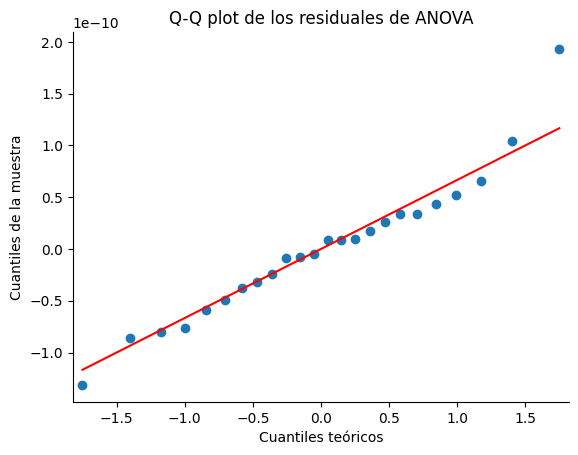

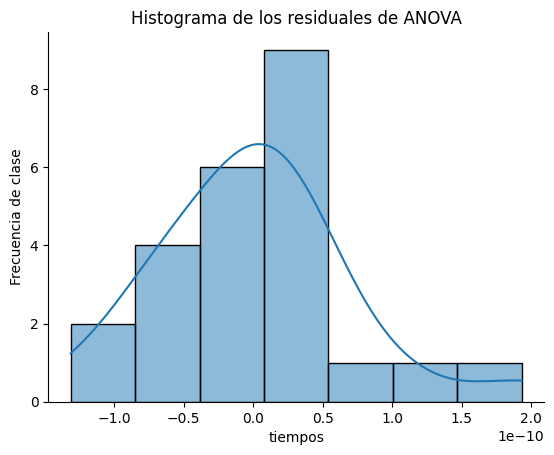

In [780]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Con la variable transformada la normalidad se cumple, por lo que los residuos de ANOVA siguen una distribución normal.

## **Levene** (con variable transformada)

In [781]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tipo_1 = df[df['Tipo'] == "A"]["Desgaste_boxcox"]
tipo_2 = df[df['Tipo'] == "B"]["Desgaste_boxcox"]
tipo_3 = df[df['Tipo'] == "C"]["Desgaste_boxcox"]
tipo_4 = df[df['Tipo'] == "D"]["Desgaste_boxcox"]

estadistico, valor_p_levene = levene(
    tipo_1,
    tipo_2,
    tipo_3,
    tipo_4,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 1.1788
Valor-p = 0.3428


### **Interpretación:** Con la variable transformada, Levene arroja un valor en donde no se rechaza la homocedasticidad y quedan cumplidos todos los supuestos del ANOVA.

## **Tukey** (con variable transformada)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower upper reject
------------------------------------------------
     A      B     -0.0    0.0  -0.0  -0.0   True
     A      C     -0.0 0.0048  -0.0  -0.0   True
     A      D     -0.0 0.0001  -0.0  -0.0   True
     B      C      0.0 0.0018   0.0   0.0   True
     B      D      0.0 0.0613  -0.0   0.0  False
     C      D     -0.0  0.401  -0.0   0.0  False
------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

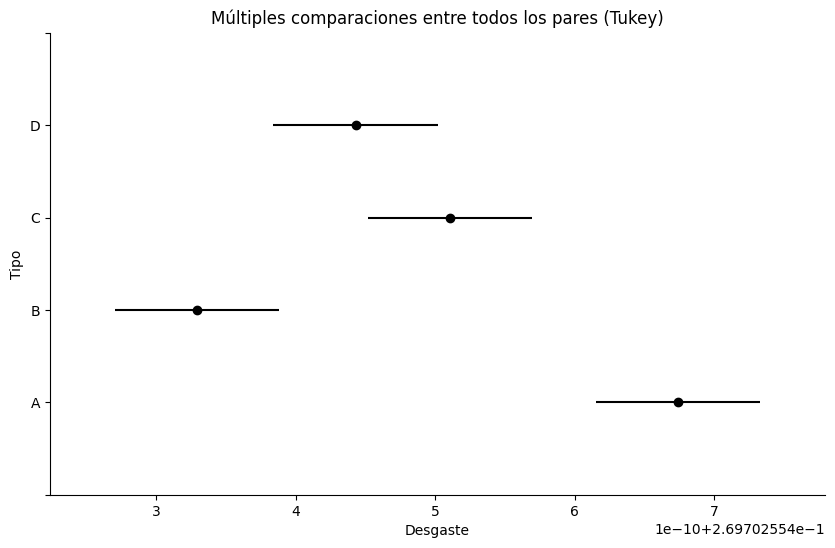

In [782]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['Desgaste_boxcox'], # Variable de respuesta
    groups=df['Tipo'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Tipo", xlabel="Desgaste")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Se utiliza Tukey por la prueba de ANOVA y commparar los tipos de cuero, por lo que expone que el cuero A es distinto y es el que más se desgatsa, mientras que el B es el de menor desgaste al igual que D.

## **Kruskal-Wallis**

In [783]:
from scipy.stats import kruskal

# Separar las calificaciones por tratamiento
tipo_A = df[df["Tipo"] == "A"]["Desgaste"]
tipo_B = df[df["Tipo"] == "B"]["Desgaste"]
tipo_C = df[df["Tipo"] == "C"]["Desgaste"]
tipo_D = df[df["Tipo"] == "D"]["Desgaste"]

# Prueba de Kruskal-Wallis
estadistico, valor_p = kruskal(
    tipo_A,
    tipo_B,
    tipo_C,
    tipo_D
    )

print(f"Estadístico de Kruskal-Wallis: {estadistico:.4f}")
print(f"Valor-p: {valor_p:.4f}")

# Aranza Yunuen Pérez Sánchez

Estadístico de Kruskal-Wallis: 16.9962
Valor-p: 0.0007


### **Interpretación:** Se utiliza la prueba no paramétrica al ANOVA a los datos origininales, rechazando la hipótesis nula. Existe evidencia de que al menos un tipo de cuero tiene  un nievl de desgaste distinto entre los demás.

In [784]:
!pip install scikit-posthocs

## **Dunn**

In [785]:
import scikit_posthocs as sp

# Dunn test con corrección de Bonferroni
resultado = sp.posthoc_dunn(
    df,
    val_col="Desgaste",
    group_col="Tipo",
    p_adjust="bonferroni"
)

resultado.round(4)

# Aranza Yunuen Pérez Sánchez

,A,B,C,D
A,1.0000,0.0004,0.7835,0.0761
B,0.0004,1.0000,0.0761,0.7835
C,0.7835,0.0761,1.0000,1.0000
D,0.0761,0.7835,1.0000,1.0000


### **Interpretación:** Corrige errores entrelazado con la prueba de Kruskal, resaltando la diferencia clara es por el cuero A y el B.

## **Eta Cuadrado**

In [786]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(Tipo)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.778


### **Interpretación:** Expone que el 77.8% de los cambios en el desgaste se deben al tipo de cuero.

## **Potencia de la prueba**

In [787]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["Tipo"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.7780
f de Cohen = 1.8722
Potencia de la prueba = 1.0000


### **Interpretación:** La potencia de la prueba indica la probabilidad de detectar una diferencia entre los tipos de cuero cuando existe, lo que resulta en 100%, indicando que el diseño tiene una capacidad para detectar el efecto.

In [788]:
n_necesario = analisis_potencia.solve_power(
 effect_size=f_cohen,
 alpha=0.05,
 power=0.80, # Potencia de la prueba
 k_groups=k_grupos
)
print(f"Observaciones totales necesarias: {n_necesario:.2f}")
print(f"Observaciones por grupo: {np.ceil(n_necesario / k_grupos):.0f}")

# Aranza Yunuen Pérez Sánchez

Observaciones totales necesarias: 8.20
Observaciones por grupo: 3


## **CONCLUSIÓN:** Se puede decir gracias a la estadística que, tras aplicar la transformación Box-Cox (lambda = -3.71) y corroborar con Kruskal-Wallis y Dunn, se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, el tipo de cuero tiene un peso grande en el desgaste con alta potencia estadística. Conviene evitar el cuero A y utilizar el cuero B para minimizar el desgaste.

# **Ejercicio 3**

3. En un centro de investigación se realiza un estudio para comparar varios tratamientos que, al aplicarse previamente a los frijoles crudos, reducen su tiempo de cocción. Estos tratamientos son a base de bicarbonato de sodio y cloruro de sodio o sal común. El primer tratamiento ($T_1$) es el de control, que consiste en no aplicar ningún tratamiento. El tratamiento $T_2$ es el remojo en agua con bicarbonato de sodio, el $T_3$ es remojar en agua con sal común y el $T_4$ es remojar en agua con una combinación de ambos ingredientes en proporciones iguales. La variable de respuesta es el tiempo de cocción en minutos. Los datos se muestran en la siguiente tabla:

| $T_1$ | $T_2$  | $T_3$  | $T_4$  |
|---------|-----|-----|-----|
| 213     | 76  | 57  | 84  |
| 214     | 85  | 67  | 82  |
| 204     | 74  | 55  | 85  |
| 208     | 78  | 64  | 92  |
| 212     | 82  | 61  | 87  |
| 200     | 75  | 63  | 79  |
| 207     | 82  | 63  | 90  |



- Factor: Tratamiento previo
- Niveles de medición: T1 (control / sin tratamiento), T2 (agua con bicarbonato de sodio), T3 (agua con sal común), T4 (combinación de ambos en partes iguales)
- Variable de respuesta: Tiempo de cocción (en minutos)
- Objetivo: minimizar

In [789]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_03.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,tratamiento,tiempo
0,T1,213
1,T2,76
2,T3,57
3,T4,84
4,T1,214
5,T2,85
6,T3,67
7,T4,82
8,T1,204
9,T2,74


## **ANOVA (diferencia entre las medias)**

In [790]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("tiempo ~ C(tratamiento)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(tratamiento),95041.2500,3.0,1558.966,0.0
Residual,487.7143,24.0,NaN,NaN


### **Interpretación:** Según ANOVA, existe evidencia para decir que al menos uno de los tratamientos previos tiene un tiempo promedio de cocción distinto a los demás, por lo que se rechaza hipótesis nula con un valor-p = 0.0000  y un estadístico F = 1558.966.

## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.34689165649615683


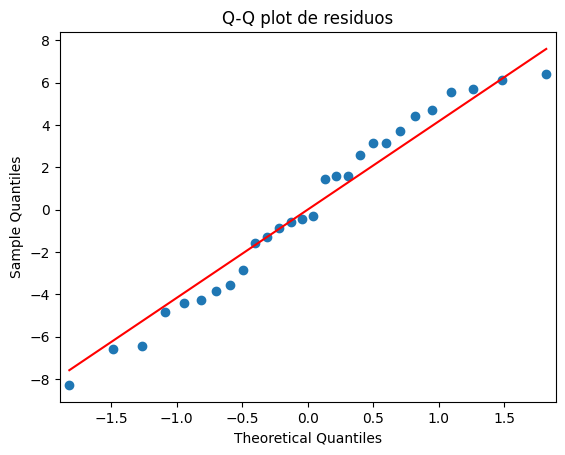

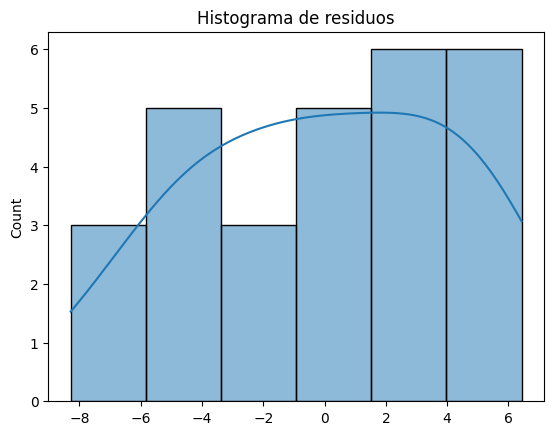

In [791]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Los resultados muestran que siendo el valor-p = 0.3469 no se rechaza la hipótesis nula de normalidad, por lo que los residuos de ANOVA siguen una distribución normal y el supuesto se cumple desde el inicio (sin necesidad de transformación)

## **Levene (Homocedasticidad)**

In [792]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
tratamiento_T1 = df[df['tratamiento'] == "T1"]["tiempo"]
tratamiento_T2 = df[df['tratamiento'] == "T2"]["tiempo"]
tratamiento_T3 = df[df['tratamiento'] == "T3"]["tiempo"]
tratamiento_T4 = df[df['tratamiento'] == "T4"]["tiempo"]

stat, p = levene(tratamiento_T1, tratamiento_T2, tratamiento_T3, tratamiento_T4)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

# Aranza Yunuen Pérez Sánchez

Estadístico de Levene: 0.1631
p-valor: 0.9201


### **Interpretación:** El valor-p resultando en 0.9201, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas del tiempo de cocción son similares entre los diferentes tratamientos.

## **Tukey**

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
    T1     T2 -129.4286    0.0 -136.0757 -122.7815   True
    T1     T3 -146.8571    0.0 -153.5043   -140.21   True
    T1     T4 -122.7143    0.0 -129.3614 -116.0672   True
    T2     T3  -17.4286    0.0  -24.0757  -10.7815   True
    T2     T4    6.7143 0.0471    0.0672   13.3614   True
    T3     T4   24.1429    0.0   17.4957     30.79   True
---------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

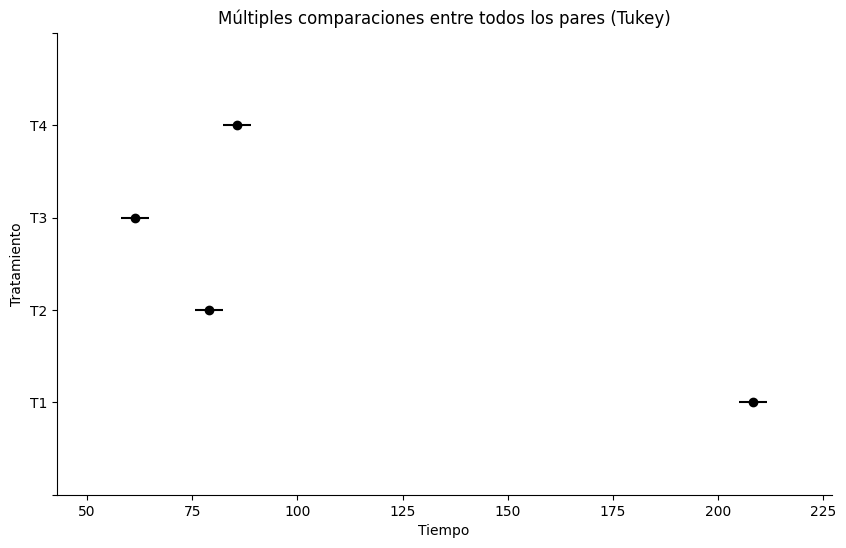

In [793]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['tiempo'], # Variable de respuesta
    groups=df['tratamiento'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Tratamiento", xlabel="Tiempo")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Todos los tratamientos son diferentes entre sí, dado que el objetivo es minimizar el tiempo de cocción, el tratamiento T3 es la mejor opción y el T1 es el que debe evitarse, por lo que utiliamos Tukey para saber qué grupo es el que cambia al recahzar la H0 de ANOVA.

## **Eta Cuadrado**

In [794]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(tratamiento)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.995


### **Interpretación:** Expone que el 99.5% de los cambios en los tiempos de cocción se deben al tratamiento aplicado.

## **Potencia de la prueba**

In [795]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["tratamiento"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.9949
f de Cohen = 13.9596
Potencia de la prueba = 1.0000


### **Interpretación:** La potencia de la prueba indica la probabilidad de detectar una diferencia entre los tratamientos cuando existe.

## **CONCLUSIÓN:** Se puede decir gracias a la estadística que se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, el tratamiento previo tiene un peso significativo en el tiempo de cocción con máxima potencia estadística. Conviene evitar el tratamiento T1 y utilizar el tratamiento T3 para minimizar el tiempo de cocción.

# **Ejercicio 4**

4. Para estudiar la confiabilidad de ciertos tableros electrónicos para carros, se someten a un envejecimiento acelerado durante 100 horas a determinada temperatura, y como variable de interés se mide la intensidad de corriente que circula entre dos puntos, cuyos valores aumentan con el deterioro. Se probaron 20 módulos repartidos de manera equitativa en cinco temperaturas y los resultados obtenidos fueron los siguientes:

| 20°C | 40°C | 60°C | 80°C | 100°C |
|------|------|------|------|-------|
| 15   | 17   | 23   | 28   | 45    |
| 18   | 21   | 19   | 32   | 51    |
| 13   | 11   | 25   | 34   | 57    |
| 12   | 16   | 22   | 31   | 48    |


- Factor: Temperatura

- Niveles de medición: 20°C, 40°C, 60°C, 80°C, 100°C

- Variable de respuesta: Intensidad de corriente

- Objetivo: Minimizar

In [796]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_04.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,temperatura,corriente
0,20C,15
1,40C,17
2,60C,23
3,80C,28
4,100C,45
5,20C,18
6,40C,21
7,60C,19
8,80C,32
9,100C,51


## **ANOVA (diferencia entre las medias)**

In [797]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("corriente ~ C(temperatura)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(temperatura),3411.8,4.0,68.0545,0.0
Residual,188.0,15.0,NaN,NaN


### **Interpretación:** Según ANOVA, existe evidencia para decir que al menos una de las temperaturas genera una intensidad de corriente promedio distinta a las demás, por lo que se rechaza H0 con un valor-p ≈ 0.0000 y un estadístico F = 68.0545.

## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.7785351257478303


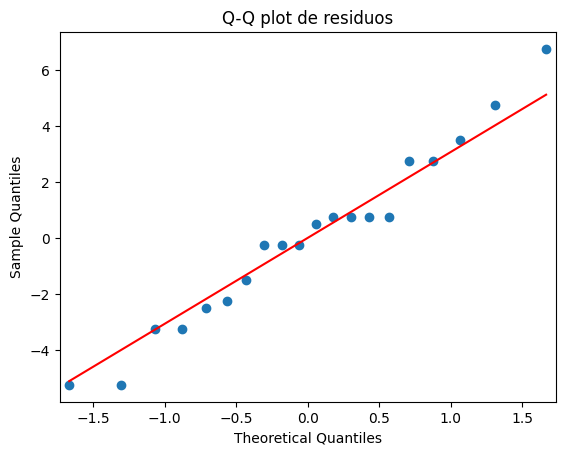

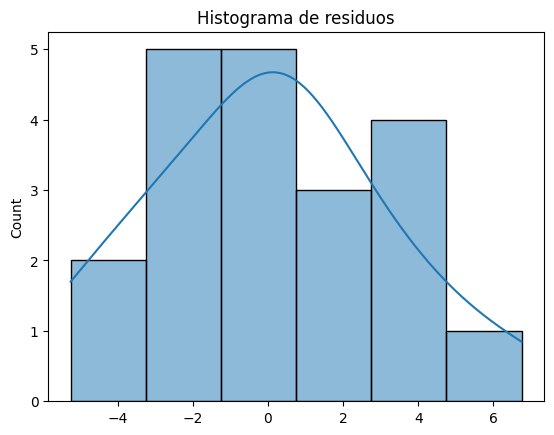

In [798]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Los resultados muestran que siendo el valor-p = 0.7785 no se rechaza la hipótesis nula de normalidad, por lo que los residuos de ANOVA siguen una distribución normal y el supuesto se cumple.

## **Levene (Homocedasticidad)**

In [799]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

temperatura_20C = df[df['temperatura'] == "20C"]["corriente"]
temperatura_40C = df[df['temperatura'] == "40C"]["corriente"]
temperatura_60C = df[df['temperatura'] == "60C"]["corriente"]
temperatura_80C = df[df['temperatura'] == "80C"]["corriente"]
temperatura_100C = df[df['temperatura'] == "100C"]["corriente"]

estadistico, valor_p_levene = levene(
    temperatura_20C,
    temperatura_40C,
    temperatura_60C,
    temperatura_80C,
    temperatura_100C,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.6808
Valor-p = 0.6160


### **Interpretación:** El valor-p resultando en 0.6160, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas de la intensidad de corriente son similares entre las diferentes temperaturas.


## **Tukey**

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
  100C    20C   -35.75    0.0 -43.4801 -28.0199   True
  100C    40C    -34.0    0.0 -41.7301 -26.2699   True
  100C    60C    -28.0    0.0 -35.7301 -20.2699   True
  100C    80C    -19.0    0.0 -26.7301 -11.2699   True
   20C    40C     1.75 0.9535  -5.9801   9.4801  False
   20C    60C     7.75 0.0493   0.0199  15.4801   True
   20C    80C    16.75 0.0001   9.0199  24.4801   True
   40C    60C      6.0 0.1696  -1.7301  13.7301  False
   40C    80C     15.0 0.0002   7.2699  22.7301   True
   60C    80C      9.0 0.0191   1.2699  16.7301   True
------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

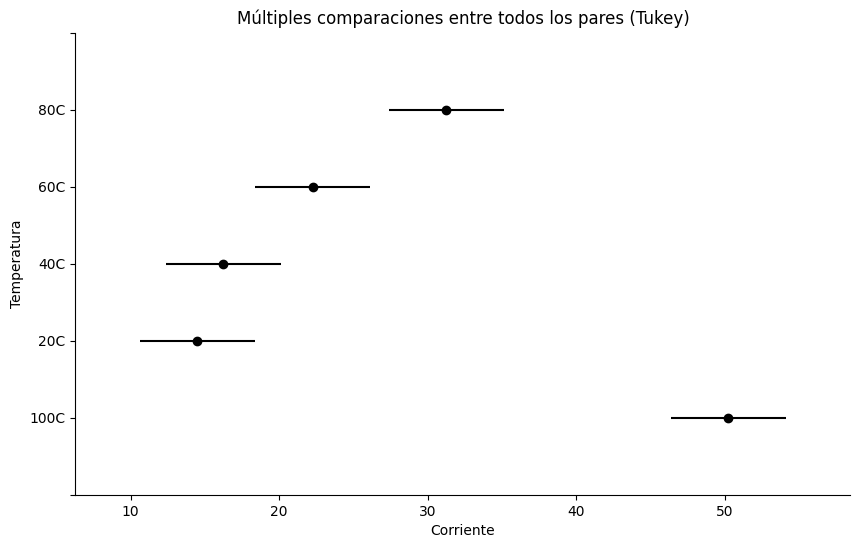

In [800]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['corriente'], # Variable de respuesta
    groups=df['temperatura'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Temperatura", xlabel="Corriente")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** La prueba post-hoc muestra diferencias significativas en casi todas las comparaciones, destacando que 100°C y 80°C son más diferentes de todas las demás temperaturas. Entre 20°C y 40°C y entre 40°C y 60°C no hay diferencia significativa, pero 20°C sí es significativamente menor que 60°C.

## **Eta Cuadrado**

In [801]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(temperatura)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.948


### **Interpretación:** Expone que el 94.8% de los cambios en la intensidad de corriente se deben a la temperatura.


## **Potencia de la prueba**

In [802]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["temperatura"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.9478
f de Cohen = 4.2600
Potencia de la prueba = 1.0000


### **Interpretación:** La potencia de la prueba indica la probabilidad de detectar una diferencia entre las temperaturas cuando existe, lo que resulta en 100%

## **CONCLUSIÓN:** Se puede decir gracias a la estadística que se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, la temperatura tiene un peso significativo en la intensidad de corriente con máxima potencia estadística. Conviene evitar las temperaturas altas, especialmente 100°C y 80°C y operar a 20°C (o 40°C) para minimizar el deterioro de los tableros electrónicos.

# **Ejercicio 5**

5. En una empresa de manufactura se propone un tratamiento para reducir el porcentaje de productos defectuosos. Para validar esta propuesta se diseñó un experimento en el que se producía con o sin la propuesta de mejora. Cada corrida experimental consistió en producir un lote y la variable de respuesta es el porcentaje de producto defectuoso. Se hicieron 25 réplicas para cada tratamiento. Los datos obtenidos se muestran a continuación:

| Tratamiento     | Porcentaje de producto defectuoso                                     |
|-----------------|----------------------------------------------------------------------|
| Con tratam.     | 5.3, 4.0, 4.0, 4.0, 2.6, 2.1, 5.1, 4.1, 4.1, 3.2, 5.1, 2.2, 4.1     |
| Sin tratam.     | 8.0, 13.2, 7.2, 8.2, 9.1, 6.7, 12.6, 16.3, 9.2, 6.4, 7.2, 17.2, 12.3 |


- Factor: Tratamiento (propuesta de mejora)
- Niveles de medición: Con tratam., sin tratam.
- Variable de respuesta: Porcentaje de producto defectuoso
- Objetivo: Minimizar

In [803]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_05.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,tratamiento,defectuoso
0,Con tratam.,5.3
1,Con tratam.,4.0
2,Con tratam.,4.0
3,Con tratam.,4.0
4,Con tratam.,2.6
5,Con tratam.,2.1
6,Con tratam.,5.1
7,Con tratam.,4.1
8,Con tratam.,4.1
9,Con tratam.,3.2


## **ANOVA (diferencia entre las medias)**

In [804]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("defectuoso ~ C(tratamiento)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(tratamiento),269.4496,1.0,37.1028,0.0
Residual,174.2938,24.0,NaN,NaN


### **Interpretación:** Con F = 37.1028 y valor-p = 0.0000, 0.0 menor a 0.05, se rechaza H0, indicando diferencia significativa en el porcentaje de defectuosos entre producir con o sin tratamiento.

## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.08240142335256262


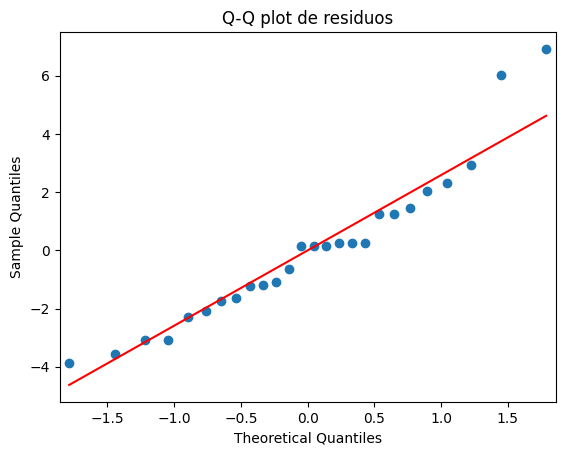

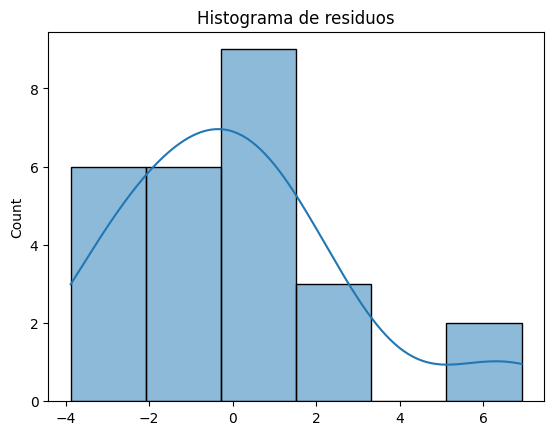

In [805]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** El valor-p = 0.0824, mayor a 0.05, indica que no se rechaza la normalidad de los residuos.

## **Levene (Homocedasticidad)**

In [806]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tratamiento_1 = df[df['tratamiento'] == 'Con tratam.']['defectuoso']
tratamiento_2 = df[df['tratamiento'] == 'Sin tratam.']['defectuoso']

estadistico, valor_p_levene = levene(
    tratamiento_1,
    tratamiento_2,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 8.7144
Valor-p = 0.0070


### **Interpretación:** Con un estadístico = 8.7144 y valor-p = 0.0070, menor a 0.05, se rechaza la hipótesis nula de homocedasticidad porque las varianzas no son iguales, por lo que no se cumple este supuesto y se requiere transformar los datos.

## **Box-Cox**

Lambda óptimo: -0.0539


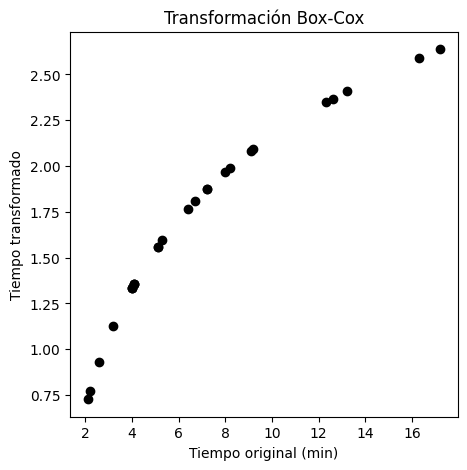

In [807]:

from scipy.stats import boxcox
import matplotlib.pyplot as plt

# Transformación Box-Cox
# Requiere que todos los valores sean mayores que cero

df["defectuoso_boxcox"], lambda_opt = boxcox(df["defectuoso"])

print(f"Lambda óptimo: {lambda_opt:.4f}")

# Visualización de la transformación
plt.figure(figsize=(5, 5), dpi=100)

plt.scatter(df["defectuoso"], df["defectuoso_boxcox"],
            color="black")

plt.title("Transformación Box-Cox")
plt.xlabel("Tiempo original (min)")
plt.ylabel("Tiempo transformado")
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Se aplica la transformación para estabilizar las varianzas y cumplir los supuestos, obteniendo un lambda = -0.0539.

## **ANOVA** (con variable transformada)

In [808]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('defectuoso_boxcox ~ C(tratamiento)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(tratamiento),5.0403,1.0,58.8438,0.0
Residual,2.0557,24.0,NaN,NaN


### **Interpretación:** Con F = 58.8438 y valor-p = 0.0000, menor a 0.05, se confirma que existe diferencia estadísticamente significativa entre ambos grupos.



## **Shapiro** (con variable transformada)

valor-p (Shapiro) = 0.5855089546322916


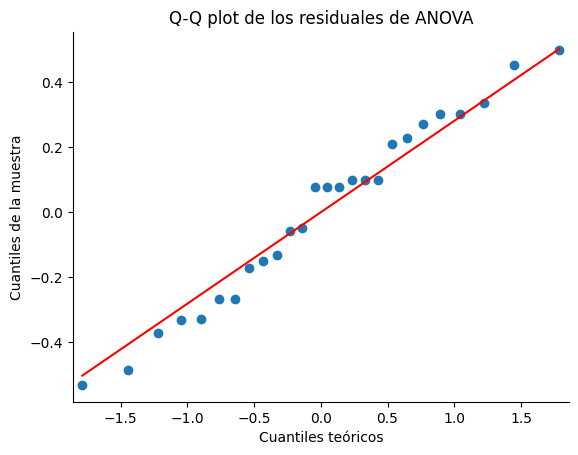

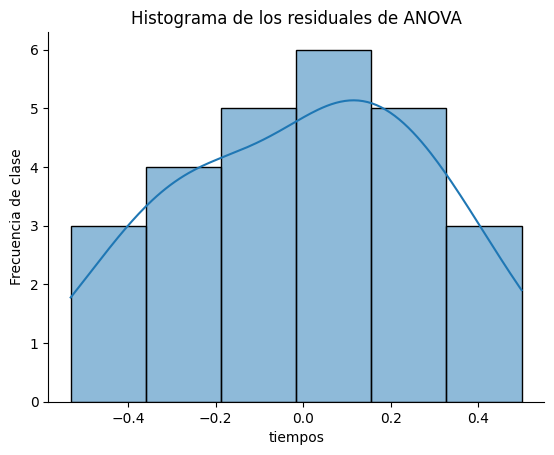

In [809]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Con valor-p = 0.5855, mayor a 0.05, se mantiene y mejora el cumplimiento del supuesto de normalidad.

## **Levene** (con variable transformada)

In [810]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tratamiento_1 = df[df['tratamiento'] == 'Con tratam.']['defectuoso_boxcox']
tratamiento_2 = df[df['tratamiento'] == 'Sin tratam.']['defectuoso_boxcox']

estadistico, valor_p_levene = levene(
    tratamiento_1,
    tratamiento_2,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.3797
Valor-p = 0.5436


### **Interpretación:** Con estadístico = 0.3797 y valor-p = 0.5436, mayor a 0.05, ya no se rechaza la homocedasticidad, logrando igualdad de varianzas y validando el ANOVA.

## **Tukey** (con variable transformada)

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
   group1      group2   meandiff p-adj lower  upper  reject
-----------------------------------------------------------
Con tratam. Sin tratam.   0.8806   0.0 0.6437 1.1175   True
-----------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

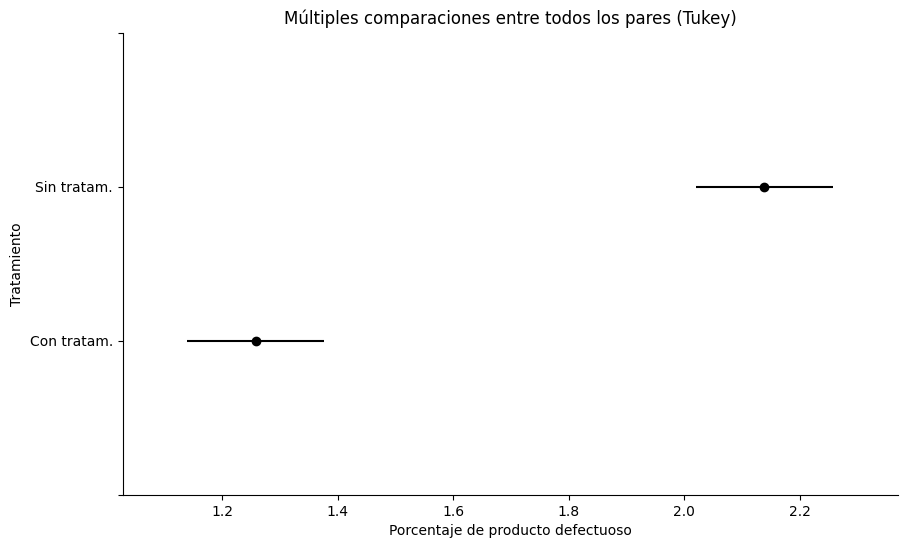

In [811]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['defectuoso_boxcox'], # Variable de respuesta
    groups=df['tratamiento'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Tratamiento", xlabel="Porcentaje de producto defectuoso")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

### **Interpretación:** Confirma una diferencia estadísticamente significativa con p-adj = 0.0 y reject = True entre con tratamiento y sin tratamiento, demostrando que aplicar la propuesta de mejora reduce el porcentaje de productos defectuosos.

## **Kruskal-Wallis**

In [812]:
from scipy.stats import kruskal

# Separar
tratamiento_1 = df[df['tratamiento'] == 'Con tratam.']['defectuoso']
tratamiento_2 = df[df['tratamiento'] == 'Sin tratam.']['defectuoso']

# Prueba de Kruskal-Wallis
estadistico, valor_p = kruskal(
     tratamiento_1,
     tratamiento_2,
)

print(f"Estadístico de Kruskal-Wallis: {estadistico:.4f}")
print(f"Valor-p: {valor_p:.4f}")

# Aranza Yunuen Pérez Sánchez

Estadístico de Kruskal-Wallis: 18.8422
Valor-p: 0.0000


### **Interpretación:** Con un estadístico de 18.8422 y valor-p = 0.0000, menor a 0.05, se rechaza la hipótesis nula, confirmando que existe diferencia significativa entre producir con o sin tratamiento sin depender de supuestos paramétricos.

In [813]:
!pip install scikit-posthocs

## **Dunn**

In [814]:
import scikit_posthocs as sp

# Dunn test con corrección de Bonferroni
resultado = sp.posthoc_dunn(
    df,
    val_col="defectuoso",
    group_col="tratamiento",
    p_adjust="bonferroni"
)

resultado.round(4)

# Aranza Yunuen Pérez Sánchez

,Con tratam.,Sin tratam.
Con tratam.,1.0,0.0
Sin tratam.,0.0,1.0


### **Interpretación:** La prueba post-hoc de Dunn con ajuste de Bonferroni muestra un valor de 0.0, menor a 0.05, entre con tratamiento y sin tratamiento, confirmando la diferencia significativa entre ambos grupos.

## **Eta Cuadrado**

In [815]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(tratamiento)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.710


### **Interpretación:** Expone que el 71.03%, de los cambios en el porcentaje de producto defectuoso se deben al tratamiento aplicado, un tamaño de efecto grande.

## **Potencia de la prueba**

In [816]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["tratamiento"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.7103
f de Cohen = 1.5658
Potencia de la prueba = 1.0000


### **Interpretación:** La potencia de la prueba resulta en 1.0000, aproximadamente 100%, lo que indica una capacidad máxima para detectar el efecto cuando existe.

## **CONCLUSIÓN:** Se puede decir gracias a la estadística que, tras aplicar la transformación Box-Cox con lambda = -0.0539 y corroborar con Kruskal-Wallis y Bonferroni, se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, el tratamiento tiene un peso significativo grande en el porcentaje de producto defectuoso. Conviene aplicar la propuesta de mejora o tratamiento y evitar producir sin tratamiento para reducir el porcentaje de productos defectuosos.


# **Ejercicio 6**

6. Una compañía farmacéutica desea evaluar el efecto que tiene la cantidad de almidón en la dureza de las tabletas. Se decidió producir lotes con una cantidad determinada de almidón, y que las cantidades de almidón a aprobar fueran 2%, 5% y 10%. La variable de respuesta sería el promedio de la dureza de 20 tabletas de cada lote. Se hicieron 4 réplicas por tratamiento y se obtuvieron los siguientes resultados:

| % de almidón | Dureza               |
|--------------|----------------------|
| 2            | 4.3, 5.2, 4.8, 4.5  |
| 5            | 6.5, 7.3, 6.9, 6.1  |
| 10           | 9.0, 7.8, 8.5, 8.1  |


- Factor: Cantidad de almidón (% de almidón)
- Niveles de medición: 2%, 5%, 10%
- Variable de respuesta: Dureza de las tabletas (promedio de 20 tabletas por lote)
- Objetivo: Evaluar el efecto

In [817]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_06.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,almidon,dureza
0,2,4.3
1,2,5.2
2,2,4.8
3,2,4.5
4,5,6.5
5,5,7.3
6,5,6.9
7,5,6.1
8,10,9.0
9,10,7.8


## **ANOVA (diferencia entre las medias)**

In [818]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("dureza ~ C(almidon)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(almidon),26.7267,2.0,58.1014,0.0
Residual,2.0700,9.0,NaN,NaN


## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.42952068080371164


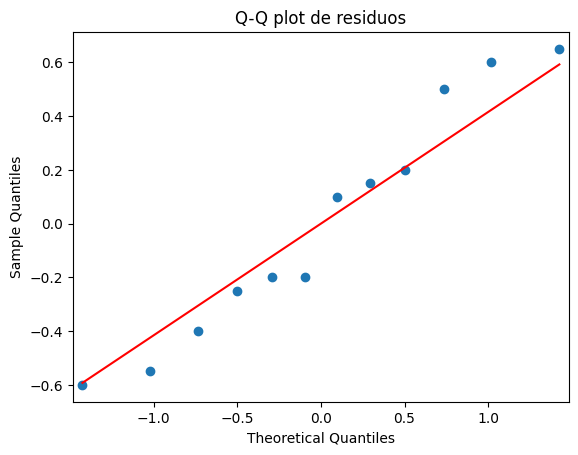

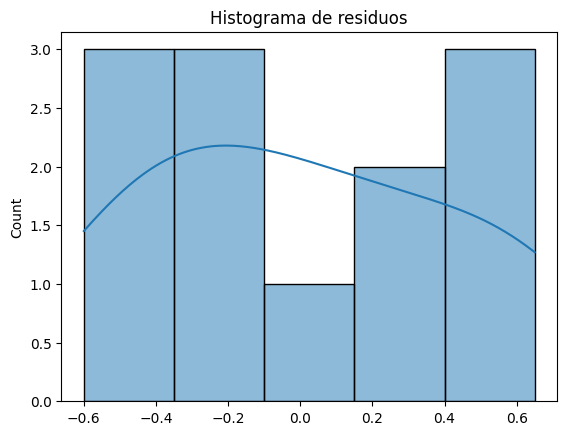

In [819]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

## **Levene (Homocedasticidad)**

In [820]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

almidon_2 = df[df['almidon'] == 2]["dureza"]
almidon_5 = df[df['almidon'] == 5]["dureza"]
almidon_10 = df[df['almidon'] == 10]["dureza"]

estadistico, valor_p_levene = levene(
    almidon_2,
    almidon_5,
    almidon_10,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.2667
Valor-p = 0.7718


## **Tukey**

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
     2      5      2.0 0.0006 1.0532 2.9468   True
     2     10     3.65    0.0 2.7032 4.5968   True
     5     10     1.65 0.0023 0.7032 2.5968   True
--------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

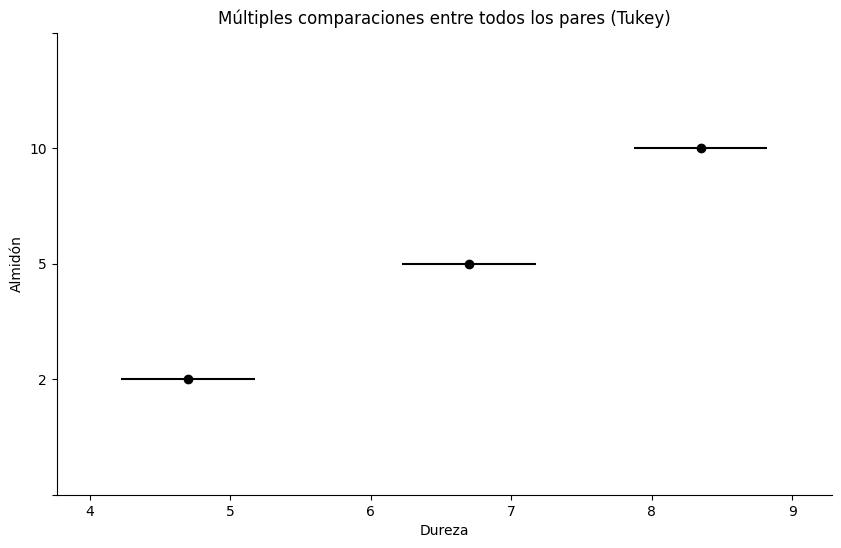

In [821]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['dureza'], # Variable de respuesta
    groups=df['almidon'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Almidón", xlabel="Dureza")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

## **Eta Cuadrado**

In [822]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(almidon)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.928


## **Potencia de la prueba**

In [823]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["almidon"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.9281
f de Cohen = 3.5932
Potencia de la prueba = 1.0000


### **Interpretación:**
**ANOVA:** Según ANOVA, existe evidencia para decir que al menos una cantidad de almidón entre 2%, 5% y 10% genera una dureza promedio distinta a las demás, por lo que se rechaza H0 con un valor-p = 0.0 menor a 0.05.

**Shapiro-Wilk:** Los resultados muestran que siendo el valor-p = 0.4295, mayor a 0.05, no se rechazs la hipótesis nula de normalidad, por lo que los residuos de ANOVA siguen una distribución normal y el supuesto se cumple.

**Levene:** El valor-p resultando en 0.7718, mayor a 0.05, con estadístico = 0.2667, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas de la dureza son similares entre los diferentes porcentajes de almidón.

**Tukey:** Todos los pares difieren significatiavmente con reject = True y valores p-adj menores a 0.05, mostrando que a mayor porcentaje de almidón aumenta la dureza promedio, siendo 10% el de mayor dureza, seguido de 5% y por último 2%.

**Eta cuadrado:** Expone que el 92.8%, 0.928 o 0.9281, de los cambios en la dureza de las tabletas se deben a la cantidad de almidón, un tamaño de efecto grande.

**Potencia:** La potencia de la prueba resulta en 100%, indicando una capacidad máxima para detectar el efecto cuando existe.


## **CONCLUSIÓN:** Se puede decir gracias a la estadística que se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, la cantidad de almidón tiene un peso significativo grande en la dureza de las tabletas con máxima potencia estadística. La elección del porcentaje de almidón entre 2%, 5% o 10% debe alinearse con el rango de dureza objetivo requerido para las tabletas, ya que cada nivel produce un promedio distinto.


# **Ejercicio 7**

7. Los datos que se presentan enseguida son rendimientos en toneladas por hectárea de un pasto con tres niveles de fertilización nitrogenada. El diseño fue completamente aleatorizado, con cinco repeticiones por tratamiento.

| Niveles de nitrógeno | Rendimientos (ton/ha)       |
|-----------------------|----------------------------|
| 1                     | 14.823, 14.676, 14.720, 14.5141, 15.065 |
| 2                     | 25.151, 25.401, 25.131, 25.031, 25.267 |
| 3                     | 32.605, 32.460, 32.256, 32.669, 32.111 |


- Factor: Nivel de fertilización nitrogenada (niveles de nitrógeno)
- Niveles de medición: 1, 2, 3
- Variable de respuesta: Rendimiento del pasto (ton/ha)
- Objetivo: Maximizar

In [824]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_07.csv"
df = pd.read_csv(link_csv)
df

,nitrogeno,rendimiento
0,1,14.8230
1,1,14.6760
2,1,14.7200
3,1,14.5141
4,1,15.0650
5,2,25.1510
6,2,25.4010
7,2,25.1310
8,2,25.0310
9,2,25.2670


## **ANOVA (diferencia entre las medias)**

In [825]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("rendimiento ~ C(nitrogeno)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(nitrogeno),788.3408,2.0,10131.6193,0.0
Residual,0.4669,12.0,NaN,NaN


## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.8890610190283172


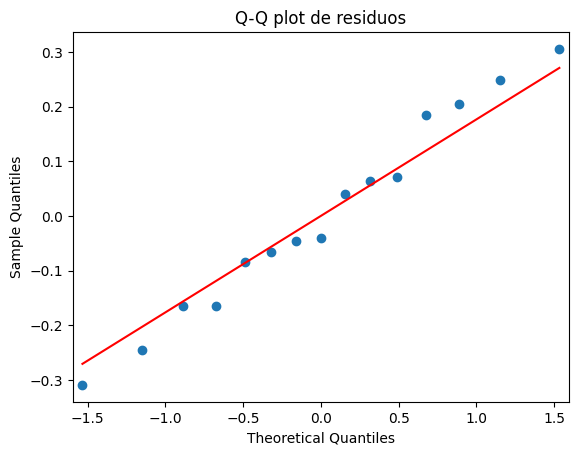

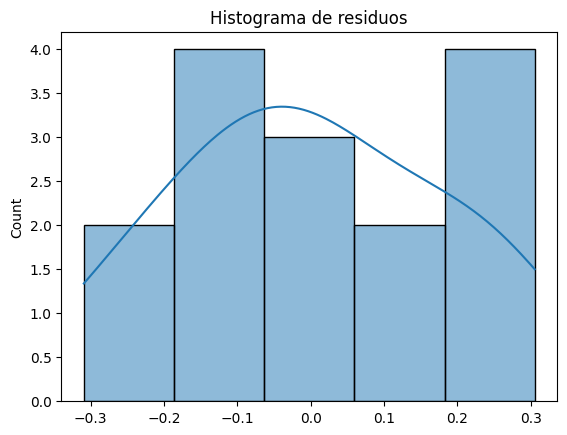

In [826]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

## **Levene (Homocedasticidad)**

In [827]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

nitrogeno_1 = df[df['nitrogeno'] == 1]["rendimiento"]
nitrogeno_2 = df[df['nitrogeno'] == 2]["rendimiento"]
nitrogeno_3 = df[df['nitrogeno'] == 3]["rendimiento"]

estadistico, valor_p_levene = levene(
    nitrogeno_1,
    nitrogeno_2,
    nitrogeno_3,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.5372
Valor-p = 0.5978


## **Tukey**

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     1      2  10.4366   0.0 10.1038 10.7694   True
     1      3  17.6606   0.0 17.3278 17.9934   True
     2      3    7.224   0.0  6.8912  7.5568   True
---------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

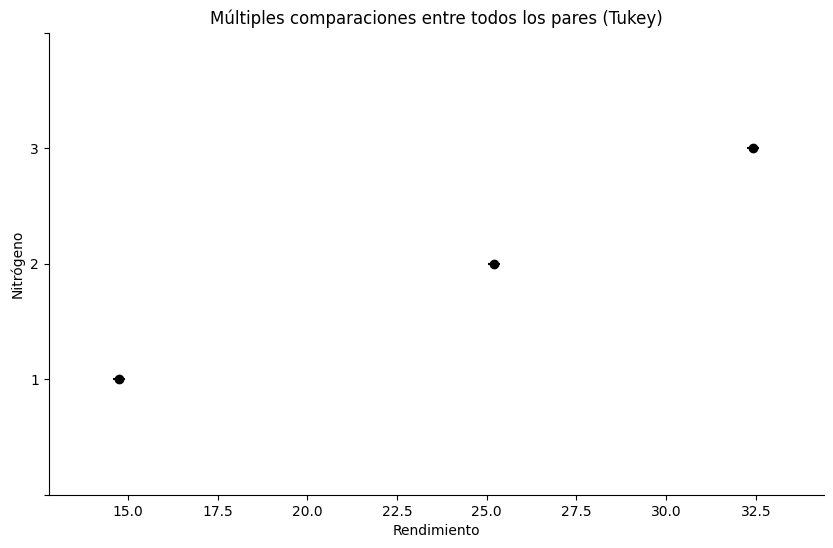

In [828]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['rendimiento'], # Variable de respuesta
    groups=df['nitrogeno'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Nitrógeno", xlabel="Rendimiento")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

## **Eta Cuadrado**

In [829]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(nitrogeno)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.999


## **Potencia de la prueba**

In [830]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["nitrogeno"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.9994
f de Cohen = 41.0926
Potencia de la prueba = 1.0000


## **Interpretación.**
**ANOVA:** Según ANOVA, existe evidencia para decir que al menos uno de los niveles de fertilización nitrogenada 1, 2 o 3 genera un rendimiento promedio de pasto distinto a los demás, por lo que se rechaza H0 con un valor-p ≈ 0.0000, 0.0 menor a 0.05,.

**Shapiro-Wilk:** Los resultados muestran que siendo el valor-p = 0.8891, mayor a 0.05, no se rechaza la hipótesis nula de normalidad, por lo que los residuos de ANOVA siguen una distribución normal y el supuesto se cumple.

**Levene:** El valor-p resultando en 0.5978, mayor a 0.05, con estadístico = 0.5372, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas del rendimiento son similares entre los diferentes niveles de nitrógeno.

**Tukey:** Todos los pares difieren significativamente con reject = True y valores p-adj = 0.0, mostrando que a mayor nivel de nitrógeno aumenta el rendimiento promedio, siendo el nivel 3 el de mayor rendimiento, seguido del nivel 2 y por último el nivel 1.

**Eta cuadrado:** Expone que el 99.9%.9994, de los cambios en el rendimiento del pasto se deben al nivel de fertilización nitrogenada, un tamaño de efecto muy grande.

**Potencia:** La potencia de la prueba resulta en aproximadamente 100%, indicando una capacidad máxima para detectar el efecto cuando existe.

## **CONCLUSIÓN:** Se puede decir gracias a la estadística que se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, el nivel de fertilización nitrogenada tiene un peso significativo muy grande en el rendimiento del pasto con máxima potencia estadística. Conviene aplicar el nivel 3 para maximizar el rendimiento del pasto y evitar el nivel 1 si el objetivo es obtener el mayor rendimiento.


# **Ejercicio 8**

8. Un químico del departamento de desarrollo de un laboratorio farmacéutico desea conocer cómo influye el tipo de aglutinante utilizado en tabletas de ampicilina de 500 mg en el porcentaje de friabilidad; para ello, se eligen los siguientes aglutinantes: polivinilpirrolidona (PVP), carboximetilcelulosa sódica (CMC) y grenetina (Gre). Los resultados del diseño experimental son los siguientes:

| Aglutinante | % de friabilidad          |
|-------------|---------------------------|
| PVP         | 0.485, 0.250, 0.073, 0.205, 0.161 |
| CMC         | 9.64, 9.37, 9.53, 9.86, 9.79       |
| Gre         | 0.289, 0.275, 0.612, 0.152, 0.137  |


- Factor: Tipo de aglutinante (en tabletas de ampicilina de 500 mg)
- Niveles de medición: PVP, CMC, Gre.
- Variable de respuesta: Porcentaje de friabilidad
- Objetivo: Minimizar

In [831]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_08.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,aglutinante,friabilidad
0,PVP,0.485
1,PVP,0.250
2,PVP,0.073
3,PVP,0.205
4,PVP,0.161
5,CMC,9.640
6,CMC,9.370
7,CMC,9.530
8,CMC,9.860
9,CMC,9.790


## **ANOVA (diferencia entre las medias)**

In [832]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("friabilidad ~ C(aglutinante)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(aglutinante),292.9210,2.0,4420.9726,0.0
Residual,0.3975,12.0,NaN,NaN


## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.42143454193876007


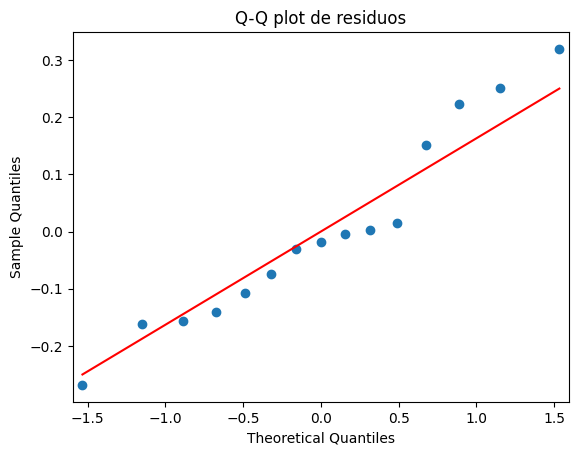

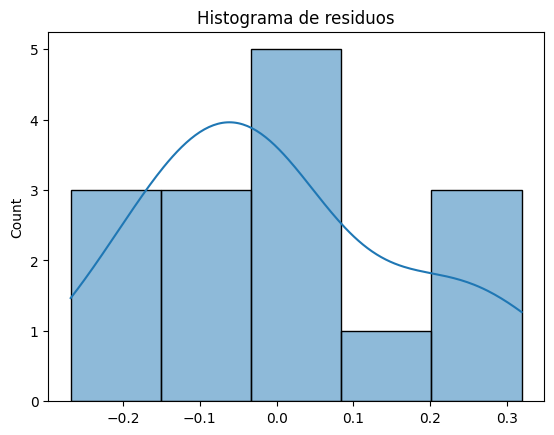

In [833]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

## **Levene (Homocedasticidad)**

In [834]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

aglutinante_PVP = df[df['aglutinante'] == "PVP"]["friabilidad"]
aglutinante_CMC = df[df['aglutinante'] == "CMC"]["friabilidad"]
aglutinante_Gre = df[df['aglutinante'] == "Gre"]["friabilidad"]

estadistico, valor_p_levene = levene(
    aglutinante_PVP,
    aglutinante_CMC,
    aglutinante_Gre,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.2250
Valor-p = 0.8018


## **Tukey**

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
   CMC    Gre   -9.345   0.0 -9.6521 -9.0379   True
   CMC    PVP  -9.4032   0.0 -9.7103 -9.0961   True
   Gre    PVP  -0.0582  0.87 -0.3653  0.2489  False
---------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

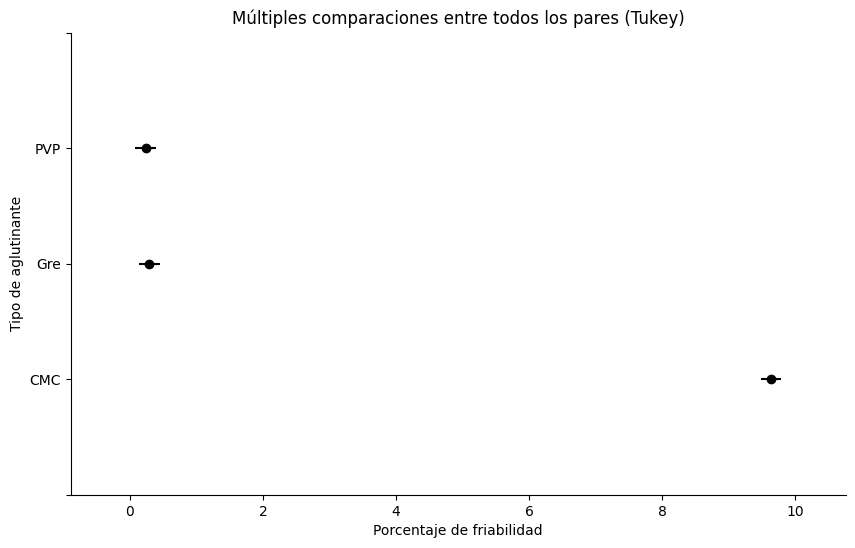

In [835]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['friabilidad'], # Variable de respuesta
    groups=df['aglutinante'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Tipo de aglutinante", xlabel="Porcentaje de friabilidad")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

## **Eta Cuadrado**

In [836]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(aglutinante)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.999


## **Potencia de la prueba**

In [837]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["aglutinante"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.9986
f de Cohen = 27.1446
Potencia de la prueba = 1.0000


### **Interpretación:**

**ANOVA:** Según ANOVA, existe evidencia para decir que al menos uno de los aglutinantes PVP, CMC o Gre genera un porcentaje de friabilidad promedio distinto a los demás, por lo que se rechaza H0 con un valor-p = 0.0000, 0.0 menor a 0.05, y un estadístico F = 4420.9726.

**Shapiro-Wilk:** Los resultados muestran que siendo el valor-p = 0.4214, mayor a 0.05, no se rechaza la hipótesis nula de normalidad, por lo que los residuos de ANOVA siguen una distribución normal y el supuesto se cumple.

**Levene:** El valor-p resultando en 0.8018, mayor a 0.05, con estadístico = 0.2250, no se rechaza la hipótesis nula de la homocedasticidad, por lo que las varianzas del porcentaje de friabilidad son similares entre los diferentes aglutinantes.

**Tukey:** CMC difiere significativamente de Gre y de PVP con reject = True y valores p-adj = 0.0, presentando un porcentaje de friabilidad mucho mayor, mientras que entre Gre y PVP no hay diferencia significativa con p-adj = 0.87 y reject = False.

**Eta cuadrado:** Expone que el 99.9%, de los cambios en el porcentaje de friabilidad se deben al tipo de aglutinante, un tamaño de efecto muy grande.

**Potencia:** La potencia de la prueba resulta en aproximadamente 100%, indicando una capacidad máxima para detectar el efecto cuando existe.


## **CONCLUSIÓN:** Se puede decir gracias a la estadística que se cumplieron los supuestos de Levene y Shapiro, por lo que ANOVA es válido y, por lo tanto, el tipo de aglutinante tiene un peso significativo muy grande en el porcentaje de friabilidad con máxima potencia estadística. Conviene evitar CMC y utilizar PVP o Gre para minimizar el porcentaje de friabilidad en las tabletas.

# **Ejercicio 9**

9. Se cultivaron cuatro diferentes clonas de *agave tequilana* bajo un mismo esquema de manejo. Se quiere saber qué clona es la que responde mejor a dicho manejo, evaluando el nivel de respuesta con el porcentaje de azúcares reductores totales en base húmeda. Los datos se muestran a continuación:

| Clona | Porcentaje de azúcares reductores totales |
|-------|------------------------------------------|
| 1     | 8.69, 6.68, 6.83, 6.43, 10.30            |
| 2     | 8.00, 16.41, 12.43, 10.99, 15.53         |
| 3     | 17.39, 13.73, 15.62, 17.05, 15.42        |
| 4     | 10.37, 9.16, 8.83, 4.40, 10.38           |


- Factor: Clona de agave tequilana
- Niveles de medición: 1, 2, 3, 4
- Variable de respuesta: Porcentaje de azúcares reductores totales (en base húmeda)
- Objetivo: Maximizar

In [838]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_09.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen Pérez Sánchez

,clona,azucares
0,1,8.69
1,1,6.68
2,1,6.83
3,1,6.43
4,1,10.30
5,2,8.00
6,2,16.41
7,2,12.43
8,2,10.99
9,2,15.53


## **ANOVA (diferencia entre las medias)**

In [839]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("azucares ~ C(clona)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(clona),209.9072,3.0,12.3271,0.0002
Residual,90.8168,16.0,NaN,NaN


## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.7677173153296


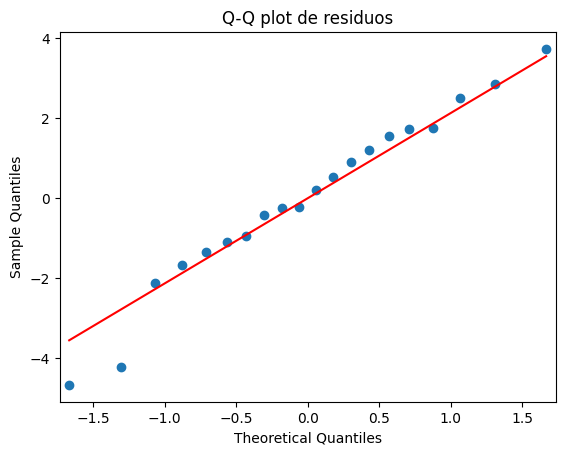

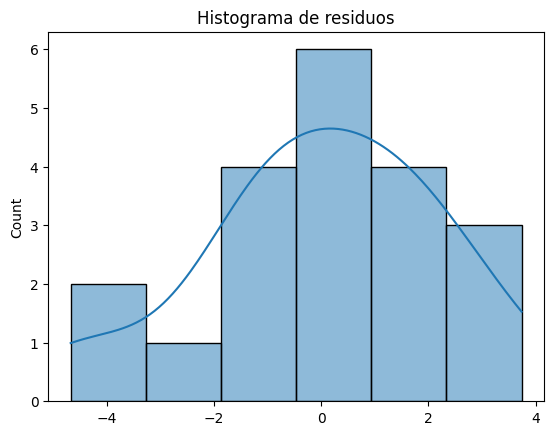

In [840]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

## **Levene (Homocedasticidad)**

In [841]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

clona_1 = df[df['clona'] == 1]["azucares"]
clona_2 = df[df['clona'] == 2]["azucares"]
clona_3 = df[df['clona'] == 3]["azucares"]
clona_4 = df[df['clona'] == 4]["azucares"]

estadistico, valor_p_levene = levene(
    clona_1,
    clona_2,
    clona_3,
    clona_4,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.9749
Valor-p = 0.4290


## **Tukey**

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2    4.886 0.0237   0.575  9.197   True
     1      3    8.056 0.0003   3.745 12.367   True
     1      4    0.842 0.9428  -3.469  5.153  False
     2      3     3.17 0.1939  -1.141  7.481  False
     2      4   -4.044 0.0699  -8.355  0.267  False
     3      4   -7.214  0.001 -11.525 -2.903   True
---------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

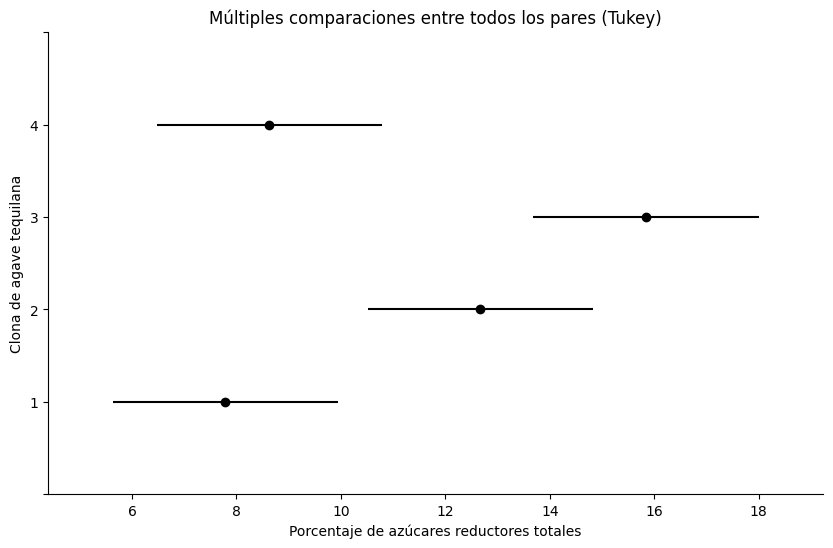

In [842]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['azucares'], # Variable de respuesta
    groups=df['clona'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Clona de agave tequilana", xlabel="Porcentaje de azúcares reductores totales")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

## **Eta Cuadrado**

In [843]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(clona)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.698


## **Potencia de la prueba**

In [844]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["clona"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.6980
f de Cohen = 1.5203
Potencia de la prueba = 0.9997


In [845]:
n_necesario = analisis_potencia.solve_power(
 effect_size=f_cohen,
 alpha=0.05,
 power=0.80, # Potencia de la prueba
 k_groups=k_grupos
)
print(f"Observaciones totales necesarias: {n_necesario:.2f}")
print(f"Observaciones por grupo: {np.ceil(n_necesario / k_grupos):.0f}")

# Aranza Yunuen Pérez Sánchez

Observaciones totales necesarias: 9.64
Observaciones por grupo: 3


# **Ejercicio 10**

10. Uno de los defectos que causan mayor desperdicio en la manufactura de discos ópticos compactos son los llamados “cometas”. Típicamente, se trata de una partícula que opone resistencia al fluido en la etapa de entintado. Se quiere comprobar de manera experimental la efectividad de un tratamiento de limpieza de partículas que está basado en fuerza centrípeta y aire ionizado. A 12 lotes de 50 CD se les aplica el tratamiento y a otros 12 lotes no se les aplica; en cada caso se mide el porcentaje de discos que presentan cometas, los resultados son los siguientes:

| Con tratamiento      | Sin tratamiento      |
|----------------------|----------------------|
| 5.30   | 8.02  |
| 4.03   | 13.18 |
| 4.00   | 7.15  |
| 2.56   | 9.11  |
| 5.06   | 8.23  |
| 4.06   | 16.3  |
| 2.08   | 9.20  |
| 4.03   | 6.35  |
| 2.04   | 7.15  |
| 1.18   | 8.66  |


- Factor: Tratamiento de limpieza de partículas
- Niveles de medición:Con tratamiento, Sin tratamiento
- Variable de respuesta: Porcentaje de discos que presentan cometas
- Objetivo: minimizar

In [846]:
import pandas as pd
link_csv = "https://raw.githubusercontent.com/Yunuenn/EstadisticaInferencial2026A/refs/heads/main/Unidad04/problema_10.csv"
df = pd.read_csv(link_csv)
df

# Aranza Yunuen pérez Sánchez

,tratamiento,cometas
0,Con tratamiento,5.30
1,Con tratamiento,4.03
2,Con tratamiento,4.00
3,Con tratamiento,2.56
4,Con tratamiento,5.06
5,Con tratamiento,4.06
6,Con tratamiento,2.08
7,Con tratamiento,4.03
8,Con tratamiento,2.04
9,Con tratamiento,1.18


## **ANOVA (diferencia entre las medias)**

In [847]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

#respuesta ~ C(factor)
modelo =ols("cometas ~ C(tratamiento)", data=df).fit()
tabla_anova =sm.stats.anova_lm(modelo,typ=2)
tabla_anova.round(4)

,sum_sq,df,F,PR(>F)
C(tratamiento),174.1090,1.0,30.6057,0.0
Residual,102.3981,18.0,NaN,NaN


## **Shapiro (Normalidad de los residuos)**

valor-p (Shapiro) = 0.013152795271816857


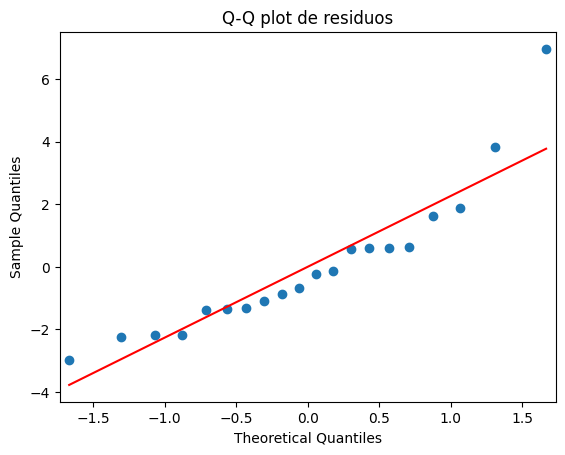

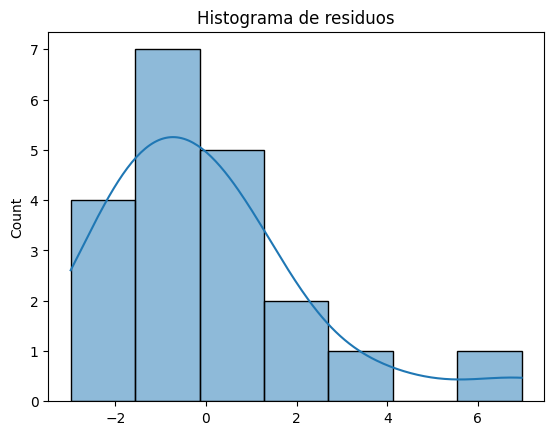

In [848]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

residuales = modelo.resid

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

# Aranza Yunuen Pérez Sánchez

## **Levene (Homocedasticidad)**

In [851]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tratamiento_Con = df[df['tratamiento'] == "Con tratamiento"]["cometas"]
tratamiento_Sin = df[df['tratamiento'] == "Sin tratamiento"]["cometas"]

estadistico, valor_p_levene = levene(
    tratamiento_Con,
    tratamiento_Sin,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 1.1180
Valor-p = 0.3043


## **Box-Cox**

Lambda óptimo: 0.3206


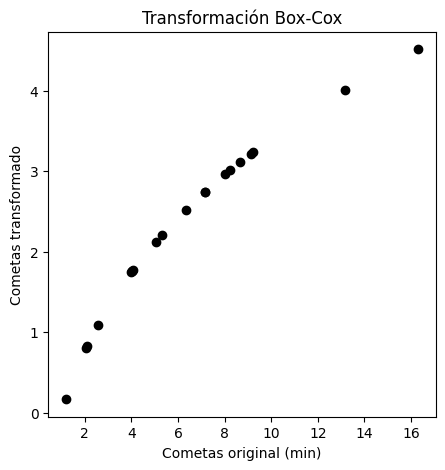

In [852]:

from scipy.stats import boxcox
import matplotlib.pyplot as plt

# Transformación Box-Cox
# Requiere que todos los valores sean mayores que cero

df["cometas_boxcox"], lambda_opt = boxcox(df["cometas"])

print(f"Lambda óptimo: {lambda_opt:.4f}")

# Visualización de la transformación
plt.figure(figsize=(5, 5), dpi=100)

plt.scatter(df["cometas"], df["cometas_boxcox"],
            color="black")

plt.title("Transformación Box-Cox")
plt.xlabel("Cometas original (min)")
plt.ylabel("Cometas transformado")
plt.show()

# Aranza Yunuen Pérez Sánchez

## **ANOVA** (con variable transformada)

In [853]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('cometas_boxcox ~ C(tratamiento)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4)

# Aranza Yunuen Pérez Sánchez

,sum_sq,df,F,PR(>F)
C(tratamiento),15.8598,1.0,38.9108,0.0
Residual,7.3367,18.0,NaN,NaN


## **Shapiro** (con variable transformada)

valor-p (Shapiro) = 0.9455348310737177


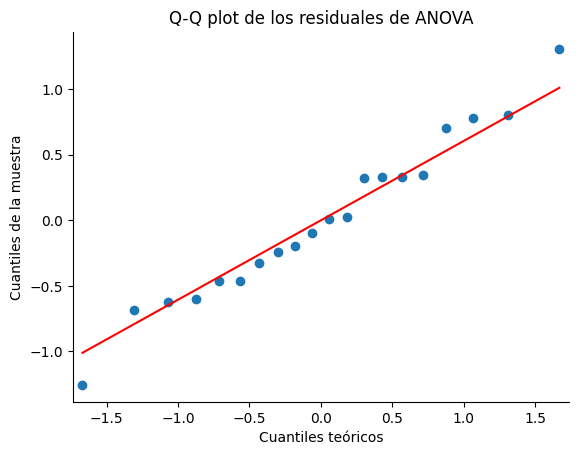

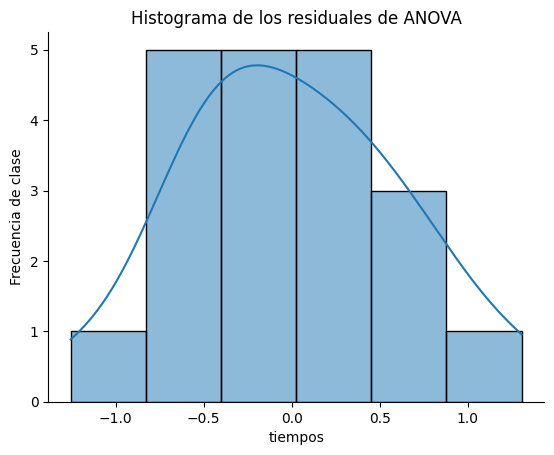

In [854]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Aranza Yunuen Pérez Sánchez

## **Levene** (con variable transformada)

In [856]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tratamiento_Con = df[df['tratamiento'] == 'Con tratamiento']['cometas_boxcox']
tratamiento_Sin = df[df['tratamiento'] == 'Sin tratamiento']['cometas_boxcox']

estadistico, valor_p_levene = levene(
    tratamiento_Con,
    tratamiento_Sin,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Aranza Yunuen Pérez Sánchez


Test de Levene (Brown-Forsythe)
Estadístico = 0.1523
Valor-p = 0.7009


## **Tukey** (con variable transformada)

        Multiple Comparison of Means - Tukey HSD, FWER=0.05        
     group1          group2     meandiff p-adj lower  upper  reject
-------------------------------------------------------------------
Con tratamiento Sin tratamiento    1.781   0.0 1.1812 2.3808   True
-------------------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

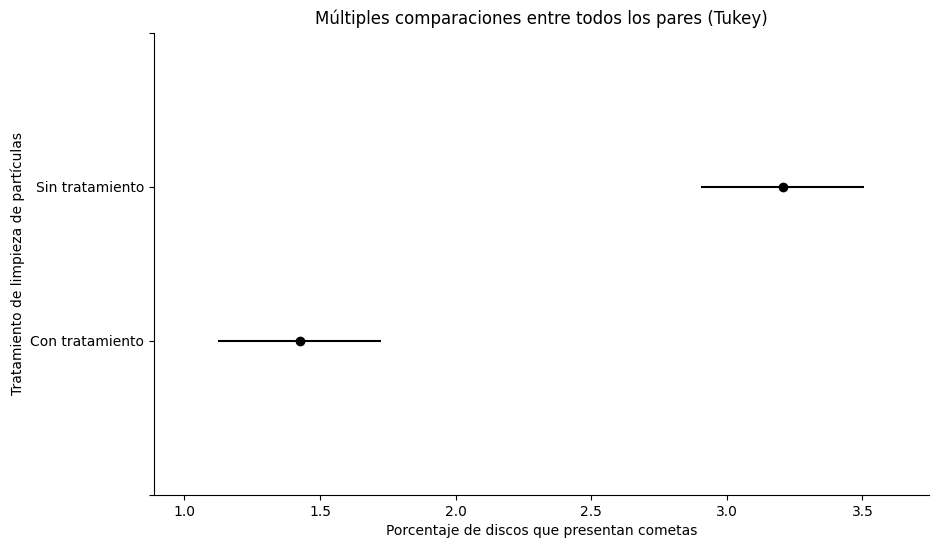

In [857]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['cometas_boxcox'], # Variable de respuesta
    groups=df['tratamiento'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Tratamiento de limpieza de partículas", xlabel="Porcentaje de discos que presentan cometas")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

# Aranza Yunuen Pérez Sánchez

## **Kruskal-Wallis**

In [858]:
from scipy.stats import kruskal

# Separar
tratamiento_Con = df[df['tratamiento'] == 'Con tratamiento']['cometas']
tratamiento_Sin = df[df['tratamiento'] == 'Sin tratamiento']['cometas']

# Prueba de Kruskal-Wallis
estadistico, valor_p = kruskal(
     tratamiento_Con,
     tratamiento_Sin,
)

print(f"Estadístico de Kruskal-Wallis: {estadistico:.4f}")
print(f"Valor-p: {valor_p:.4f}")

# Aranza Yunuen Pérez Sánchez

Estadístico de Kruskal-Wallis: 14.3072
Valor-p: 0.0002


In [859]:
!pip install scikit-posthocs

## **Bonferroni**

In [860]:
import scikit_posthocs as sp

# Dunn test con corrección de Bonferroni
resultado = sp.posthoc_dunn(
    df,
    val_col="cometas",
    group_col="tratamiento",
    p_adjust="bonferroni"
)

resultado.round(4)

# Aranza Yunuen Pérez Sánchez

,Con tratamiento,Sin tratamiento
Con tratamiento,1.0000,0.0002
Sin tratamiento,0.0002,1.0000


## **Eta Cuadrado**

In [861]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(tratamiento)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

# Aranza Yunuen Pérez Sánchez

η² (tamaño de efecto): 0.684


## **Potencia de la prueba**

In [862]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["tratamiento"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

# Aranza Yunuen Pérez Sánchez

η² = 0.6837
f de Cohen = 1.4703
Potencia de la prueba = 1.0000
